# Proyecto IA de Inspiración biológica
## Indice
1. [Introducción al Problema](#introducción-al-problema)
2. [Modelos Biológicos](#modelos-de-inspiración-biológica)
3. [Coevolución](#idea-coevolutiva)
## Introducción al Problema

Para este proyecto tenemos dos conjuntos de datos: (1) `Diabetes.csv`, (2) `California.csv`. No entraremos en detalles de cómo son estos datos, sus variables, etc. ya que no es demasiado relevante para nuestro problema. Lo que debemos saber, es que tenemos un conjunto de variables $X_1, ..., X_n$ para cada dataset y una variable "target" que llamaremos $Y$. 

En el caso del dataset *Diabetes* tenemos 10 variables más el target (`target`). Para el dataset *California* tenemos 8 variables más el target (`MedHouseVal`). Ambos targets son valores numéricos que queremos inferir a partir de nuestro set de variables. Sin embargo, en este proyecto no queremos hacer el mejor modelo para inferir los datos. Lo que queremos, es poner en práctica nuestros conocimientos en IA de inspiración biológica de manera que aprendamos nuevas variables, tal que con una simple regresión, podamos inferir mejor nuestros datos. Para las regresiones lineales, utilizaremos el código de [geekforgeeks](https://www.geeksforgeeks.org/machine-learning/linear-regression-python-implementation/) que hemos escrito en `basic_regresor`.

Pero cómo definimos formalmente nuestro problema? Nuestra pregunta es, sómos capaces de hayar nuevos atributos $A_1, \ldots, A_m$ de manera que:

1. Sean funciones de $X_1,\ldots,X_n$ y no utilicen el target. Es decir,
$$
A_i:\mathbb{R}^n\rightarrow \mathbb{R}
$$
2. Son independientes entre observaciones. Es decir, no hemos mezclado observaciones para calcular nuevos atributos. Es más, para calcular los nuevos atributos debemos utilizar las variables, no las observaciones; con las observaciones evaluamos nuestras nuevas variables.

3. Las variables mejoran la regresión.

Entonces, podemos entender una solución a nuestro problema cómo un conjunto de variables $\{A_1(X_1,\ldots,X_n),\ldots,A_m(X_1,\ldots, X_n)\}$. 

Notemos que todavía no hemos definido ni cuantas variables nuevas queremos, ni cómo evaluaremos la solución ni cómo la codificaremos. Sólo hemos entendido qué es una solución.

Para evaluar una solución, podemos analizar el $r2-score$ de una regresión lineal. Por ejemplo, en el siguiente código, sin calcular nuevos atributos, hemos hecho una regresión lineal simple, en un subconjunto de los datos (train) y luego los hemos testeado:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataprocessor import datos_test_train
from basic_regresor import MultipleLinearRegression, SimpleLinearRegression

In [2]:
# Cargar los datos
dfDiabetes = pd.read_csv("rawdata/Diabetes.csv")
dfCalifornia = pd.read_csv("rawdata/California.csv")

In [3]:
proporcion = 0.2
seed = 321938
dfD_train, dfD_test = datos_test_train(dfDiabetes, test_size=proporcion, seed=seed)
dfC_train, dfC_test = datos_test_train(dfCalifornia, test_size=proporcion, seed=seed)

In [4]:
dfDiabetes.head(5)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [5]:
dfCalifornia.head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Multiple LR Coefficients: [ 151.82560076   -8.65237747 -268.78833572  566.11467439  346.63373682
 -832.46372247  459.66886999  130.77473786  243.64881685  724.57993631
   46.39161237]
R² Score: 0.53


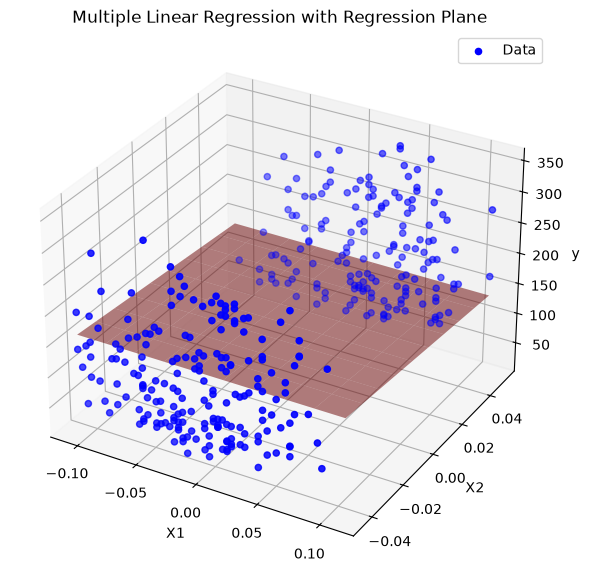

In [6]:
MLRD = MultipleLinearRegression()
XD_train = dfD_train.iloc[:,:-1].to_numpy()
XD_test = dfD_test.iloc[:,:-1].to_numpy()
yD_train = dfD_train.iloc[:,-1].to_numpy()
yD_test = dfD_test.iloc[:,-1].to_numpy()
MLRD.plot(XD_train, yD_train)

Multiple LR Coefficients: [-3.63420376e+01  4.41820031e-01  9.02938929e-03 -1.16545126e-01
  6.60516757e-01 -4.87422475e-06 -3.47030156e-03 -4.16106107e-01
 -4.28176664e-01]
R² Score: 0.61


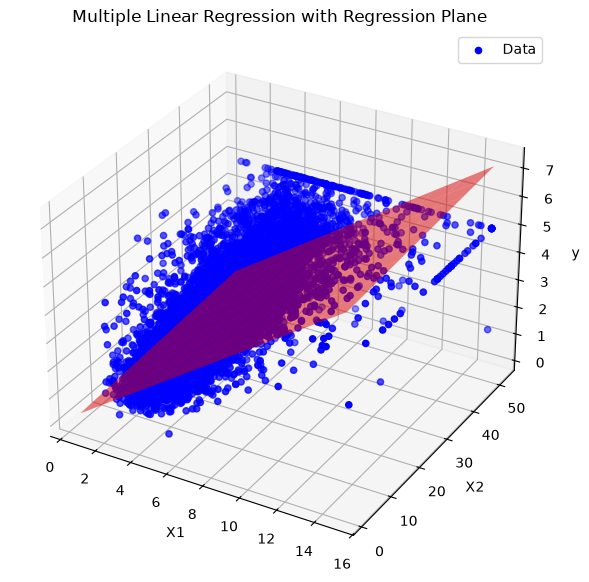

In [7]:
MLRC = MultipleLinearRegression()
XC_train = dfC_train.iloc[:,:-1].to_numpy()
XC_test = dfC_test.iloc[:,:-1].to_numpy()
yC_train = dfC_train.iloc[:,-1].to_numpy()
yC_test = dfC_test.iloc[:,-1].to_numpy()
MLRC.plot(XC_train, yC_train)

In [8]:
# Definimos tabla precisiones
y_pred_diabetes = MLRD.predict(XD_test)
r2score_diab = 1 - (np.sum((yD_test - y_pred_diabetes)**2)/np.sum((yD_test - np.mean(yD_test))**2))

y_pred_cali = MLRC.predict(XC_test)
r2score_cali = 1 - (np.sum((yC_test - y_pred_cali)**2)/np.sum((yC_test - np.mean(yC_test))**2))

results = pd.DataFrame({'Test Size': [proporcion], 'Diabetes': [r2score_diab], 'California': [r2score_cali]})
results

,Test Size,Diabetes,California
0,0.2,0.469179,0.604488


# Modelos Biologicos

Para nuestros modelos biologicos, utilizaremos el lenguaje karva. Veamos algunos ejemploes del lenguaje Karva y asi comprovamos cómo funciona. Es importante mencionar algunas cosas importantes 

In [1]:
from utils import *
from gepkarva import gen, Cromosoma

import matplotlib.pyplot as plt

In [2]:
seed = 12123
rng = np.random.default_rng(seed)

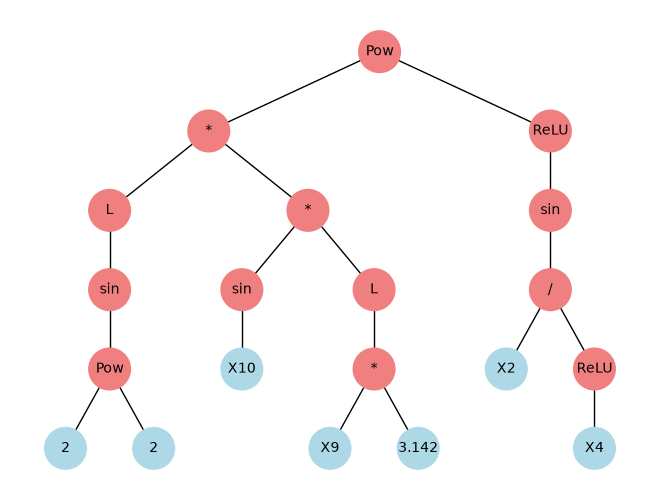

In [14]:
g1 = gen(n_vars=10,
         h=15)
g1.aleatorio(rng)
g1.plot_gen()
plt.show()

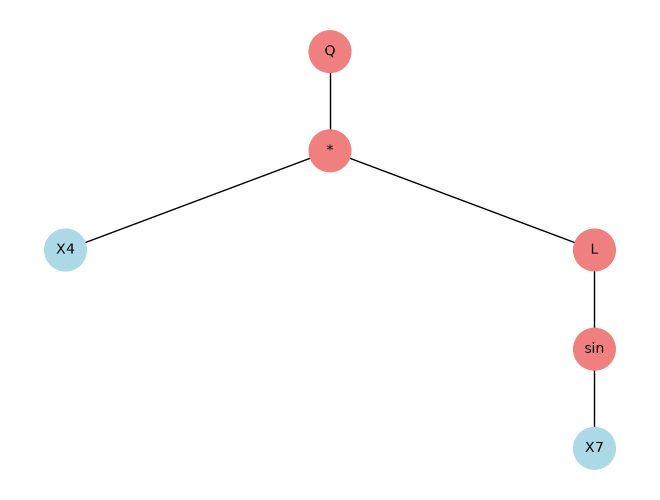

In [15]:
mutacion(g1, 0.5, rng)
g1.plot_gen()
plt.show()

### Viabilidad

**La idea**: dos poblaciones, una por atributo ($A_1$, $A_2$), que compiten por un recurso común: el **peso en la regresión**. Cada individuo se evalúa junto a parejas de la otra población (la mejor y alguna al azar, como la *life-time fitness* de los apuntes). El recurso se mide con el coeficiente estandarizado
$$p_i=\frac{|\beta_i|\,\mathrm{std}(A_i)}{\sum_j |\beta_j|\,\mathrm{std}(A_j)},\qquad \text{fitness}_i=r^2\cdot\big[(1-\lambda)+\lambda\, m\, p_i\big]$$
con $\lambda\in[0,1]$ la intensidad de la competencia ($\lambda=0$: cooperativa, solo $r^2$; $\lambda=1$: competencia pura). Hay que **estandarizar** con $\mathrm{std}(A_i)$ porque, si no, un atributo "gana" coeficiente simplemente por tener otra escala.

**Argumentos a favor**
* Encaja en la coevolución competitiva: el éxito de uno es presión sobre el otro (Reina Roja); si $A_2$ es irrelevante su peso $\to 0$ y tiene presión para mejorar, algo que un único cromosoma con fitness global no hace.
* Poblaciones pequeñas de un solo gen, y la regresión sigue ajustándose al máximo.

**Argumentos en contra (riesgos)**
1. **El recurso se puede "hackear" con colinealidad.** Si $A_i$ es casi combinación lineal de las $X$ (o de su rival), el reparto de coeficientes es arbitrario: se puede *ganar peso sin aportar información*. En una primera versión, sin controlarlo, la competencia pura eligió `(age - s4)` y `s4`: peso alto, ninguna información nueva.
2. **El objetivo real (mejorar $r^2$) y el recurso (peso) no están alineados**: un peso grande no implica un mejor modelo.
3. **Fitness ruidoso/no estacionario**: depende de la pareja, que cambia cada generación.
4. Coste: cada individuo se evalúa con varias parejas.

**Veredicto**: es *viable de programar* y didáctico, pero solo con salvaguardas (estandarizar, rechazar atributos colineales) y mejor como competencia **suave** que pura. Lo comprobamos con un ejemplo.